<a href="https://colab.research.google.com/github/Azizkhan-23/Deep-Learning-and-NLP-Spam-Classifier/blob/main/Deep_Learning_NLP_Spam_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset shape:", df.shape)
display(df.head())
print(df["label"].value_counts())


Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:

df = df.dropna(subset=["message", "label"])
df = df.drop_duplicates(subset=["message"])

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    df["message"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train = vectorizer.fit_transform(X_train_text).toarray()
X_test = vectorizer.transform(X_test_text).toarray()

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train_text)
y_test = encoder.transform(y_test_text)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", list(encoder.classes_))


Training samples: 4135
Testing samples: 1034
Classes: ['ham', 'spam']


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),
    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 649,217 (2.48 MB)

 Trainable params: 648,833 (2.48 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7349 - loss: 0.5631 - val_accuracy: 0.8791 - val_loss: 0.4071
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9368 - loss: 0.1943 - val_accuracy: 0.8803 - val_loss: 0.2592
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9828 - loss: 0.0806 - val_accuracy: 0.9492 - val_loss: 0.1541
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9840 - loss: 0.0559 - val_accuracy: 0.9770 - val_loss: 0.0909
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9879 - loss: 0.0414 - val_accuracy: 0.9867 - val_loss: 0.0547
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9958 - loss: 0.0230 - val_accuracy: 0.9903 - val_loss: 0.0412
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9958 - loss: 0.0211 - val_accuracy: 0.9915 - val_loss: 0.0374
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9964 - loss: 0.0182 - val_accu

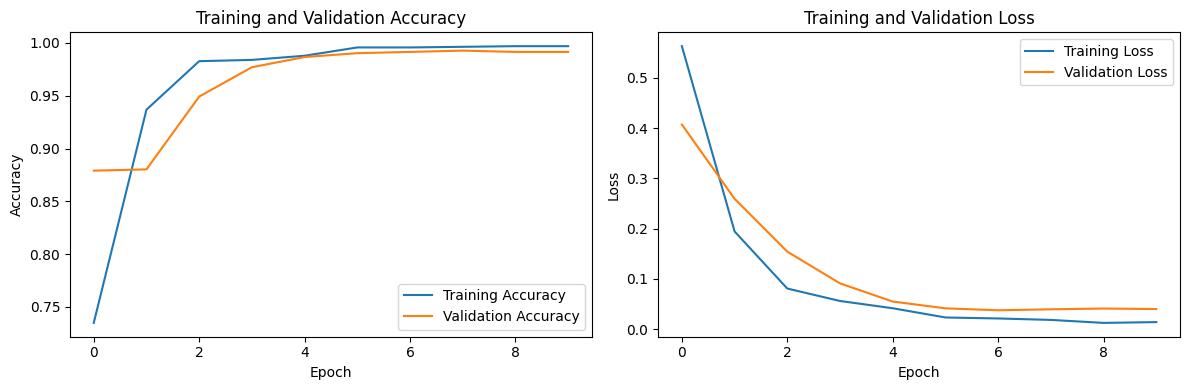

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.86      0.92       131

    accuracy                           0.98      1034
   macro avg       0.98      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



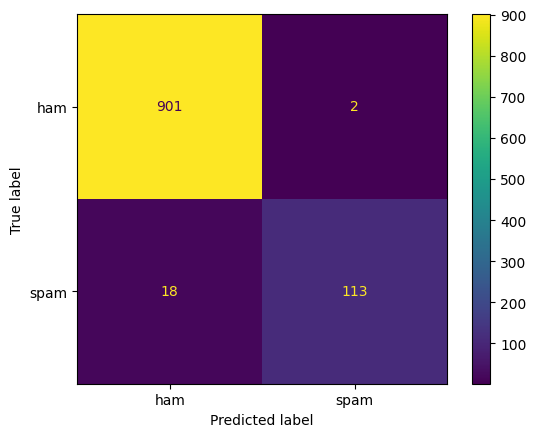

In [ ]:

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
).plot()
plt.show()


In [ ]:

def predict_message(message):
    features = vectorizer.transform([message]).toarray()
    spam_probability = float(model.predict(features, verbose=0)[0][0])

    label = "spam" if spam_probability >= 0.5 else "ham"
    confidence = spam_probability if label == "spam" else 1 - spam_probability

    print("Message:", message)
    print("Prediction:", label.upper())
    print(f"Confidence: {confidence:.2%}")
    print(f"Spam probability: {spam_probability:.2%}")

predict_message("Congratulations! You have won a free prize. Call now!")
print()
predict_message("Hi bro, are we meeting tomorrow?")


Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Confidence: 99.96%
Spam probability: 99.96%

Message: Hi bro, are we meeting tomorrow?
Prediction: HAM
Confidence: 99.21%
Spam probability: 0.79%
